[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/DANIFUZZY1975/estadistica-descriptiva-python/blob/main/notebooks/04_trampas_de_la_media.ipynb)

# 🦖 Las trampas de la media (y por qué SIEMPRE hay que dibujar los datos)

**Estadística Descriptiva · 1.º Grado en Ciencia de Datos · UCM**

Cuatro historias cortas en las que los números resumen **mienten** (o, mejor dicho, no cuentan toda la verdad):

1. **Bill Gates entra en un bar**: la media se vuelve loca y la mediana ni se inmuta.
2. **El cuarteto de Anscombe** (1973): cuatro conjuntos con la misma media, varianza, correlación… y **la misma recta de regresión**.
3. **El Datasaurus**: trece conjuntos con los mismos estadísticos. Uno de ellos es un dinosaurio.
4. **Cinco distribuciones con el mismo diagrama de caja**.
5. **La paradoja de Simpson**: ¿discriminaba la Universidad de Berkeley a las mujeres en 1973?

In [1]:
# ============================================================
# 0. Librerías, estilo y funciones de apoyo
# ============================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda v: f"{v:,.4g}" if v != 0 and abs(v) < 0.01 else f"{v:,.3f}")

sns.set_theme(style="whitegrid", context="notebook")
AZUL, NARANJA, VERDE, AMARILLO = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
plt.rcParams.update({"figure.figsize": (10, 4), "axes.titleweight": "bold"})

# Los datos se leen del repositorio de GitHub, así el notebook funciona
# igual en Colab, en Jupyter local o en VS Code sin subir nada a mano.
URL_DATOS = "https://raw.githubusercontent.com/DANIFUZZY1975/estadistica-descriptiva-python/main/data/"

def cargar(nombre, **kwargs):
    """Busca el CSV en local (../data o carpeta actual); si no está, lo baja de GitHub."""
    for ruta in (os.path.join("..", "data", nombre), os.path.join("data", nombre), nombre):
        if os.path.exists(ruta):
            return pd.read_csv(ruta, **kwargs)
    return pd.read_csv(URL_DATOS + nombre, **kwargs)


def moda(x, bins="sturges"):
    """Moda:
    - variable discreta (pocos valores distintos) -> valor más repetido;
    - variable continua -> moda INTERPOLADA dentro de la clase modal del histograma:
          Mo = L + d1 / (d1 + d2) * a
      con L = extremo inferior de la clase modal, a = su amplitud,
          d1 = n_i - n_(i-1)  (diferencia con la clase de la izquierda),
          d2 = n_i - n_(i+1)  (diferencia con la clase de la derecha).
      Es el punto donde se cortan las rectas que unen, en cruz, las esquinas superiores
      de la barra modal con las de sus vecinas: si la vecina izquierda es más alta,
      la moda se desplaza a la izquierda, y al revés. Siempre queda dentro de la clase modal."""
    x = pd.Series(x).dropna()
    if x.nunique() <= 30:
        return x.mode().iloc[0]
    frec, bordes = np.histogram(x, bins=bins)
    i = frec.argmax()
    n_izq = frec[i - 1] if i > 0 else 0
    n_der = frec[i + 1] if i < len(frec) - 1 else 0
    d1, d2 = frec[i] - n_izq, frec[i] - n_der
    L, a = bordes[i], bordes[i + 1] - bordes[i]
    if d1 + d2 == 0:          # meseta: las tres barras iguales -> punto medio
        return L + a / 2
    return L + d1 / (d1 + d2) * a


def limites_tukey(x, k=1.5):
    """Vallas de Tukey: [Q1 - k·IQR , Q3 + k·IQR] (las del diagrama de caja)."""
    q1, q3 = np.nanquantile(x, [0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr


def resumen(x):
    """Todas las medidas descriptivas de una variable cuantitativa en una Serie."""
    x = pd.Series(x).dropna().astype(float)
    q1, me, q3 = x.quantile([0.25, 0.50, 0.75])
    li, ls = limites_tukey(x)
    return pd.Series({
        # --- tamaño
        "n": x.size,
        # --- medidas de posición central
        "media": x.mean(),
        "mediana": me,
        "moda": moda(x),
        "media_recortada_5%": stats.trim_mean(x, 0.05),  # quita el 5 % de CADA cola
        # --- medidas de posición no central
        "min": x.min(), "Q1": q1, "Q3": q3, "max": x.max(),
        # --- medidas de dispersión
        "rango": x.max() - x.min(),
        "IQR": q3 - q1,
        "varianza": x.var(),          # cuasivarianza (divide entre n-1)
        "desv_tipica": x.std(),       # cuasidesviación típica (n-1)
        "CV_%": 100 * x.std() / abs(x.mean()) if x.mean() != 0 else np.nan,
        "MAD": stats.median_abs_deviation(x),  # mediana de |x - mediana|
        # --- medidas de forma
        "asimetria_Fisher": x.skew(),
        "asimetria_Pearson": 3 * (x.mean() - me) / x.std(),
        "curtosis_exceso": x.kurt(),  # 0 = como la normal
        # --- anómalos
        "n_atipicos_Tukey": int(((x < li) | (x > ls)).sum()),
    })


def histograma_con_centros(x, titulo="", bins="sturges", ax=None, color=AZUL):
    """Histograma + KDE con media, mediana y moda marcadas."""
    x = pd.Series(x).dropna()
    ax = ax or plt.gca()
    sns.histplot(x, bins=bins, kde=True, color=color, alpha=0.35, ax=ax)
    for valor, etiqueta, estilo in [(x.mean(), "media", "-"),
                                    (x.median(), "mediana", "--"),
                                    (moda(x, bins=bins), "moda", ":")]:
        ax.axvline(valor, color="#333333", ls=estilo, lw=2,
                   label=f"{etiqueta} = {valor:,.2f}")
    ax.set_title(titulo or x.name)
    ax.legend(frameon=False)
    return ax


# ============================================================
# Regresión: lineal, potencial y exponencial
# ============================================================
def r2(y_obs, y_pred):
    """Coeficiente de determinación: 1 - SCresidual / SCtotal."""
    y_obs, y_pred = np.asarray(y_obs, float), np.asarray(y_pred, float)
    return 1 - np.sum((y_obs - y_pred) ** 2) / np.sum((y_obs - y_obs.mean()) ** 2)


def recta_minimos_cuadrados(x, y):
    """Recta de regresión de y sobre x:  y = a + b·x,
    b = S_xy / S_x^2   y   a = media(y) - b·media(x)."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    sxy = np.mean((x - x.mean()) * (y - y.mean()))
    sx2 = np.mean((x - x.mean()) ** 2)
    b = sxy / sx2
    a = y.mean() - b * x.mean()
    return a, b


def regresiones(x, y):
    """Ajusta los tres modelos por mínimos cuadrados.
    - Lineal:      y = a + b·x
    - Potencial:   y = a·x^b      ->  ln y = ln a + b·ln x   (exige x > 0 e y > 0)
    - Exponencial: y = a·e^(b·x)  ->  ln y = ln a + b·x      (exige y > 0)
    Devuelve (tabla, modelos), donde modelos[nombre] es una función que predice y."""
    datos = pd.DataFrame({"x": x, "y": y}).dropna()
    x, y = datos["x"].to_numpy(float), datos["y"].to_numpy(float)
    filas, modelos = [], {}

    a, b = recta_minimos_cuadrados(x, y)
    modelos["lineal"] = lambda t, a=a, b=b: a + b * np.asarray(t, float)
    filas.append({"modelo": "lineal", "ecuación": f"y = {a:,.4g} + {b:,.4g}·x", "a": a, "b": b,
                  "R2 (escala del ajuste)": r2(y, modelos["lineal"](x)),
                  "R2 (escala original)": r2(y, modelos["lineal"](x))})

    if (x > 0).all() and (y > 0).all():
        A, b = recta_minimos_cuadrados(np.log(x), np.log(y))
        a = np.exp(A)
        modelos["potencial"] = lambda t, a=a, b=b: a * np.asarray(t, float) ** b
        filas.append({"modelo": "potencial", "ecuación": f"y = {a:,.4g}·x^{b:,.4g}", "a": a, "b": b,
                      "R2 (escala del ajuste)": r2(np.log(y), A + b * np.log(x)),
                      "R2 (escala original)": r2(y, modelos["potencial"](x))})
    else:
        filas.append({"modelo": "potencial", "ecuación": "no aplicable: necesita x > 0 e y > 0"})

    if (y > 0).all():
        A, b = recta_minimos_cuadrados(x, np.log(y))
        a = np.exp(A)
        modelos["exponencial"] = lambda t, a=a, b=b: a * np.exp(b * np.asarray(t, float))
        filas.append({"modelo": "exponencial", "ecuación": f"y = {a:,.4g}·e^({b:,.4g}·x)", "a": a, "b": b,
                      "R2 (escala del ajuste)": r2(np.log(y), A + b * x),
                      "R2 (escala original)": r2(y, modelos["exponencial"](x))})
    else:
        filas.append({"modelo": "exponencial", "ecuación": "no aplicable: necesita y > 0"})

    return pd.DataFrame(filas).set_index("modelo"), modelos


COLOR_MODELO = {"lineal": AZUL, "potencial": NARANJA, "exponencial": VERDE}


def dibujar_regresiones(x, y, modelos, ax=None, n_puntos=3000, xlabel=None, ylabel=None, titulo=""):
    """Nube de puntos + las curvas ajustadas (si hay muchos puntos, se dibuja una muestra)."""
    datos = pd.DataFrame({"x": x, "y": y}).dropna()
    muestra = datos.sample(min(n_puntos, len(datos)), random_state=1)
    ax = ax or plt.gca()
    ax.scatter(muestra["x"], muestra["y"], s=10, alpha=0.3, color="#9aa0a6")
    xs = np.linspace(datos["x"].min(), datos["x"].max(), 300)
    for nombre, f in modelos.items():
        ax.plot(xs, f(xs), lw=2.5, color=COLOR_MODELO[nombre], label=nombre)
    ax.set_xlabel(xlabel or getattr(x, "name", "x")); ax.set_ylabel(ylabel or getattr(y, "name", "y"))
    ax.set_title(titulo); ax.legend(frameon=False)
    return ax

---
# 🕐 Sesión 1 de 1 · Por qué hay que dibujar los datos
**Objetivos:** robustez de la media y la mediana, límites de los resúmenes numéricos y del R², paradoja de Simpson.  
**Apartados:** 1 a 5 · **Duración orientativa:** 2 horas

## 1. Bill Gates entra en un bar
En un bar hay 10 personas con sueldos normales (en miles de € al año). Entra Bill Gates.

In [2]:
sueldos = pd.Series([18, 21, 22, 24, 25, 27, 28, 31, 35, 40], name="sueldo")
con_gates = pd.concat([sueldos, pd.Series([1_000_000])], ignore_index=True)

comparacion = pd.DataFrame({
    "sin Gates": [sueldos.mean(), sueldos.median(), stats.trim_mean(sueldos, 0.1), sueldos.std(), sueldos.quantile(.75) - sueldos.quantile(.25)],
    "con Gates": [con_gates.mean(), con_gates.median(), stats.trim_mean(con_gates, 0.1), con_gates.std(), con_gates.quantile(.75) - con_gates.quantile(.25)],
}, index=["media", "mediana", "media recortada 10%", "desv. típica", "IQR"])
comparacion.round(1)

,sin Gates,con Gates
media,27.100,"90,933.700"
mediana,26.000,27.000
media recortada 10%,26.600,28.100
desv. típica,6.700,"301,503.200"
IQR,7.800,10.000


🤔 Con Gates en el bar, **la persona media es millonaria**, pero nadie (salvo uno) lo es.
La mediana y el IQR apenas cambian: son medidas **robustas**. La media y la desviación típica, no.
¿Qué medida usarías para hablar del "sueldo típico" de un país?

## 2. El cuarteto de Anscombe
En 1973 el estadístico Francis Anscombe construyó cuatro conjuntos de 11 puntos para demostrar que **hay que dibujar los datos**.

In [3]:
ans = cargar("anscombe.csv")
def estadisticos_xy(g):
    a, b = recta_minimos_cuadrados(g["x"], g["y"])
    return pd.Series({"media_x": g["x"].mean(), "media_y": g["y"].mean(),
                      "var_x": g["x"].var(), "var_y": g["y"].var(),
                      "r": g["x"].corr(g["y"]), "recta_a": a, "recta_b": b,
                      "R2": g["x"].corr(g["y"]) ** 2})

ans.groupby("dataset")[["x", "y"]].apply(estadisticos_xy).round(2)

,media_x,media_y,var_x,var_y,r,recta_a,recta_b,R2
dataset,,,,,,,,
I,9.000,7.500,11.000,4.130,0.820,3.000,0.500,0.670
II,9.000,7.500,11.000,4.130,0.820,3.000,0.500,0.670
III,9.000,7.500,11.000,4.120,0.820,3.000,0.500,0.670
IV,9.000,7.500,11.000,4.120,0.820,3.000,0.500,0.670


Los cuatro tienen, a dos decimales, **la misma media, la misma varianza, la misma correlación y la misma recta de regresión**
($y = 3 + 0{,}5\,x$, con $R^2 = 0{,}67$). ¿Son iguales? Dibujémoslos:

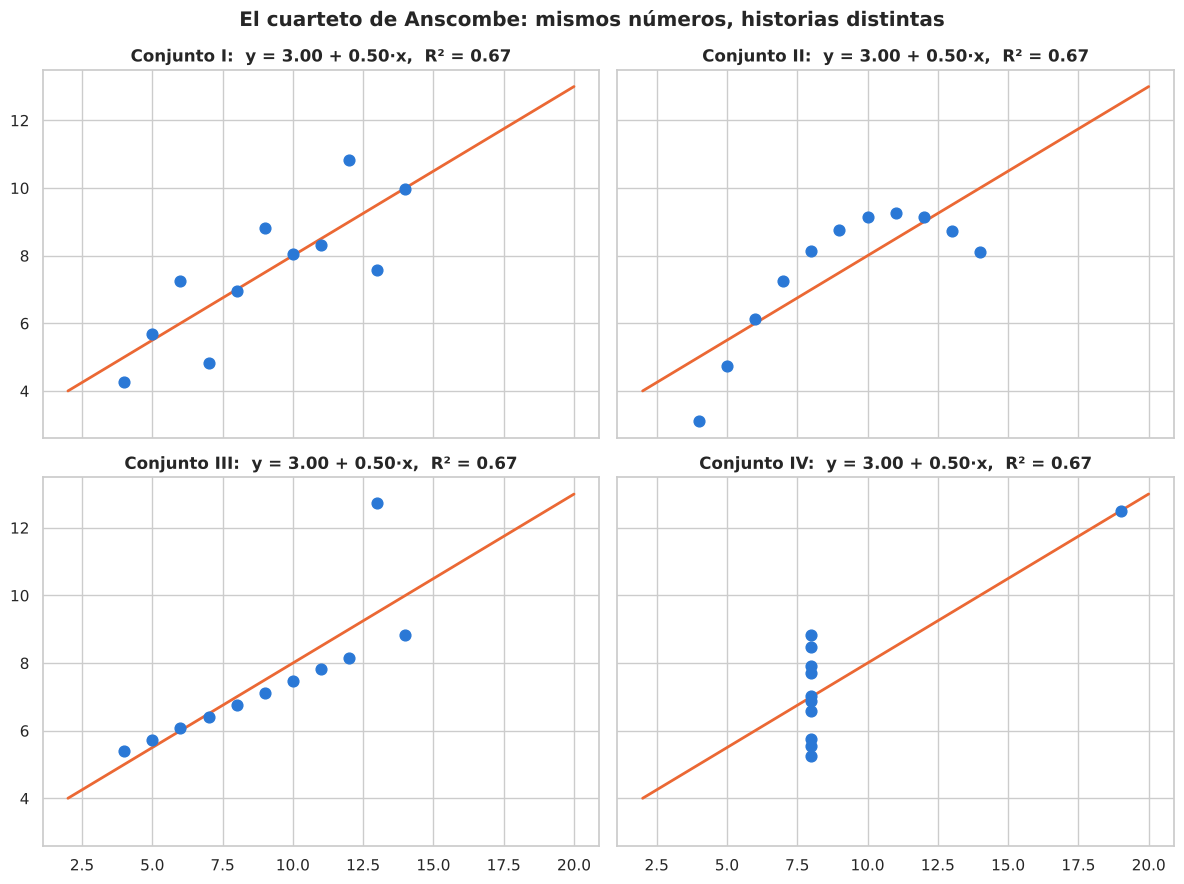

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9), sharex=True, sharey=True)
xs = np.linspace(2, 20, 50)
for ax, (nombre, g) in zip(axes.flat, ans.groupby("dataset")):
    a, b = recta_minimos_cuadrados(g["x"], g["y"])
    ax.scatter(g["x"], g["y"], s=60, color=AZUL, zorder=3)
    ax.plot(xs, a + b * xs, color=NARANJA, lw=2)
    ax.set_title(f"Conjunto {nombre}:  y = {a:.2f} + {b:.2f}·x,  R² = {g['x'].corr(g['y'])**2:.2f}")
plt.suptitle("El cuarteto de Anscombe: mismos números, historias distintas", fontweight="bold")
plt.tight_layout(); plt.show()

- **I**: la recta tiene sentido.
- **II**: la relación es **curva**; una recta es el modelo equivocado (y ni el potencial ni el exponencial son la forma correcta: es una parábola).
- **III**: una relación casi perfecta… y **un atípico** que tuerce la recta.
- **IV**: no hay relación ninguna entre x e y; **un único punto** "fabrica" la correlación.

🎯 El $R^2$ no dice si el modelo es el adecuado. **Solo el gráfico (y los residuos) lo dicen.**

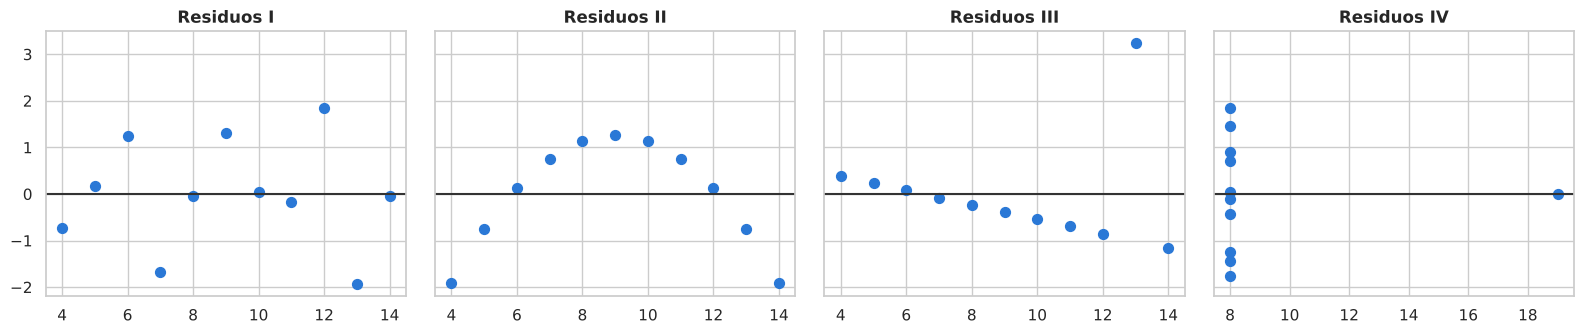

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5), sharey=True)
for ax, (nombre, g) in zip(axes, ans.groupby("dataset")):
    a, b = recta_minimos_cuadrados(g["x"], g["y"])
    ax.scatter(g["x"], g["y"] - (a + b * g["x"]), s=50, color=AZUL)
    ax.axhline(0, color="#333333"); ax.set_title(f"Residuos {nombre}")
plt.tight_layout(); plt.show()

🤔 ¿En qué conjunto los residuos forman una **parábola**? ¿En cuál hay **un residuo enorme**? Los residuos delatan el problema
aunque el $R^2$ sea idéntico.

## 3. El Datasaurus
En 2017, Justin Matejka y George Fitzmaurice llevaron la idea al extremo: **13 conjuntos** de 142 puntos con los mismos estadísticos.
Primero, solo los números:

In [6]:
dino = cargar("datasaurus_dozen.tsv", sep="\t")
tabla_dino = dino.groupby("dataset")[["x", "y"]].apply(estadisticos_xy).round(2)
tabla_dino

,media_x,media_y,var_x,var_y,r,recta_a,recta_b,R2
dataset,,,,,,,,
away,54.270,47.830,281.230,725.750,-0.060,53.430,-0.100,0.000
bullseye,54.270,47.830,281.210,725.530,-0.070,53.810,-0.110,0.000
circle,54.270,47.840,280.900,725.230,-0.070,53.800,-0.110,0.000
dino,54.260,47.830,281.070,725.520,-0.060,53.450,-0.100,0.000
dots,54.260,47.840,281.160,725.240,-0.060,53.100,-0.100,0.000
h_lines,54.260,47.830,281.100,725.760,-0.060,53.210,-0.100,0.000
high_lines,54.270,47.840,281.120,725.760,-0.070,53.810,-0.110,0.000
slant_down,54.270,47.840,281.120,725.550,-0.070,53.850,-0.110,0.000
slant_up,54.270,47.830,281.190,725.690,-0.070,53.810,-0.110,0.000


🤔 **Antes de seguir:** ¿cuál de los 13 es un dinosaurio? Con la tabla es imposible saberlo. Ahora dibujamos:

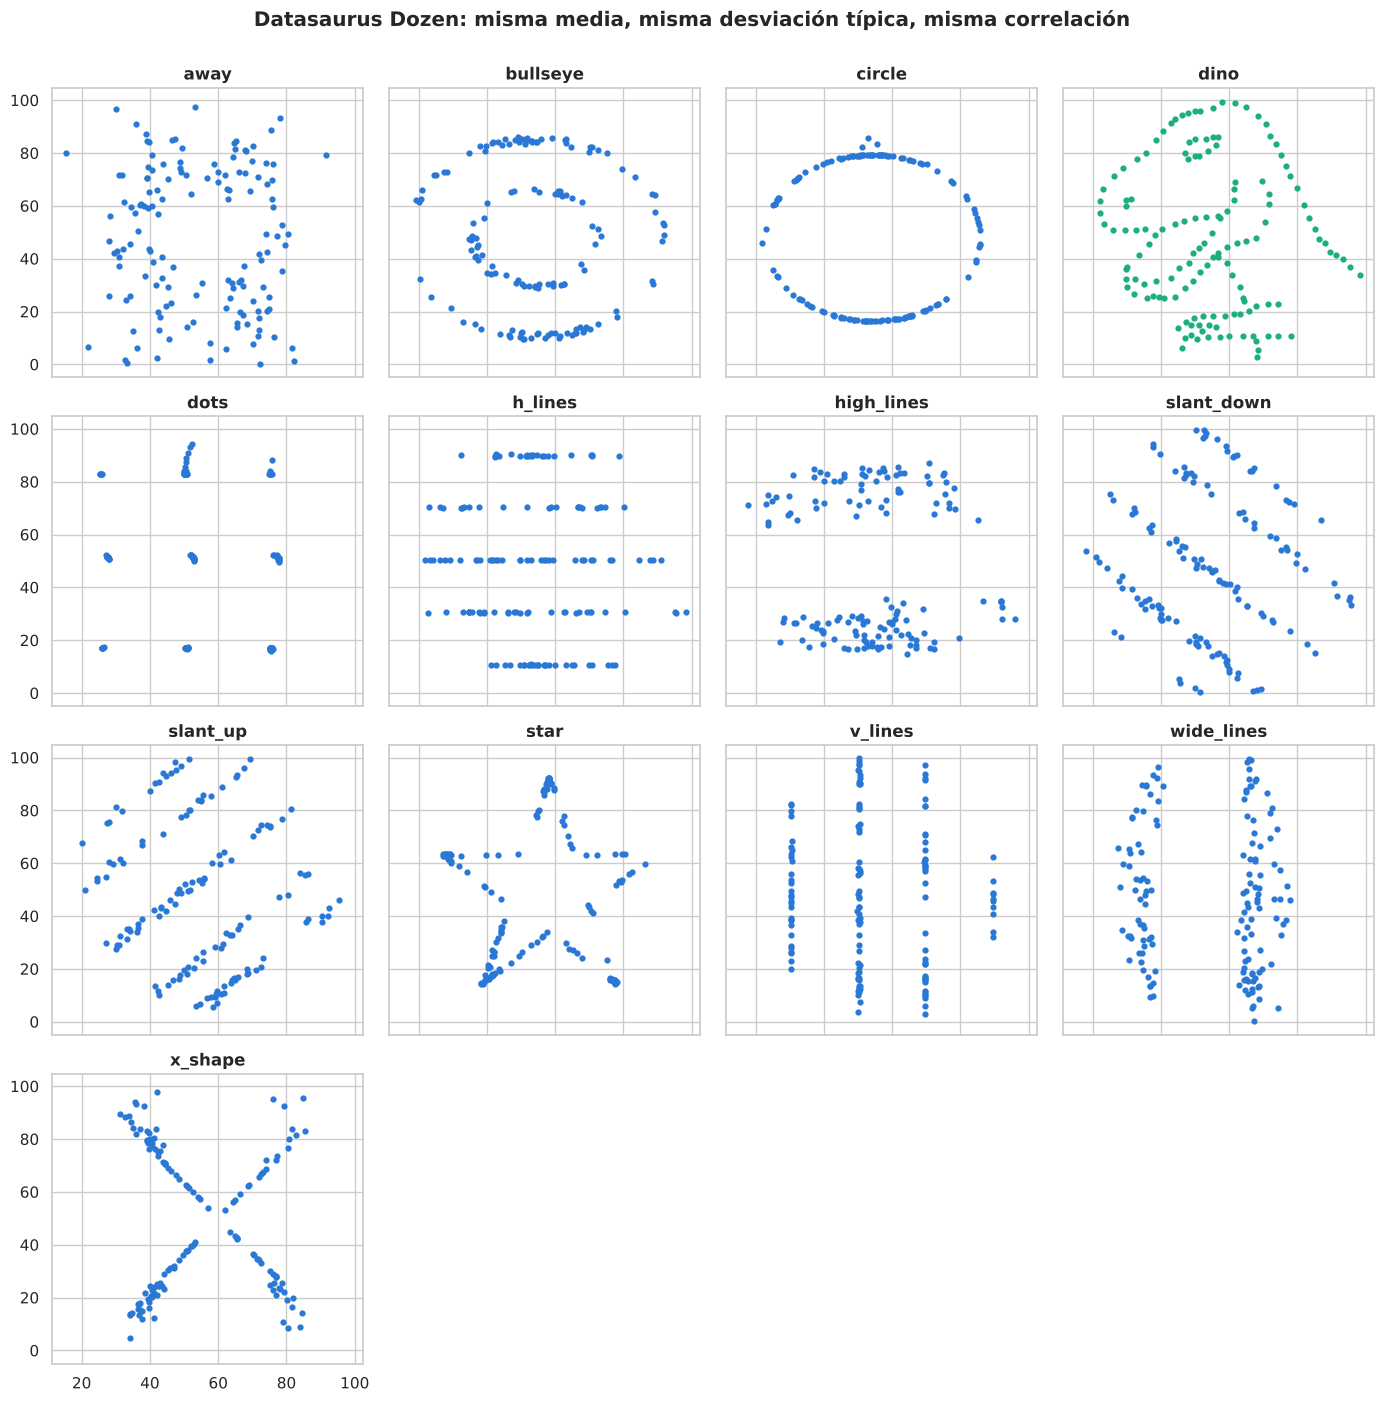

In [7]:
fig, axes = plt.subplots(4, 4, figsize=(14, 14), sharex=True, sharey=True)
for ax, (nombre, g) in zip(axes.flat, dino.groupby("dataset")):
    ax.scatter(g["x"], g["y"], s=12, color=VERDE if nombre == "dino" else AZUL)
    ax.set_title(nombre)
for ax in axes.flat[dino["dataset"].nunique():]:
    ax.axis("off")
plt.suptitle("Datasaurus Dozen: misma media, misma desviación típica, misma correlación", fontweight="bold", y=1.0)
plt.tight_layout(); plt.show()

🦖 Y todos tienen además prácticamente **la misma recta de regresión**, casi horizontal ($r \approx -0{,}06$, $R^2 \approx 0$).
Un $R^2$ de 0 no significa "no hay ninguna relación": significa "no hay relación **lineal**". ¡Hay un dinosaurio!

## 4. Cinco distribuciones, un solo diagrama de caja
El diagrama de caja resume una variable en 5 números (mín., Q1, mediana, Q3, máx.). ¿Basta con eso?

In [8]:
cajas = cargar("mismo_boxplot.tsv", sep="\t").rename(columns={"Plot": "distribucion", "Values": "valor"})
cajas.groupby("distribucion")["valor"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
distribucion,,,,,,,,
left,"2,484.000",-1.180,3.900,-9.770,-2.690,-0.010,2.670,9.750
lines,"2,484.000",-0.830,3.880,-9.770,-2.690,-0.010,2.670,9.760
normal,"2,484.000",-0.000,3.840,-9.760,-2.680,-0.000,2.680,9.760
right,"2,484.000",1.170,3.900,-9.760,-2.680,-0.000,2.680,9.760
split,"2,484.000",-0.000,4.980,-9.770,-2.690,-0.000,2.680,9.760


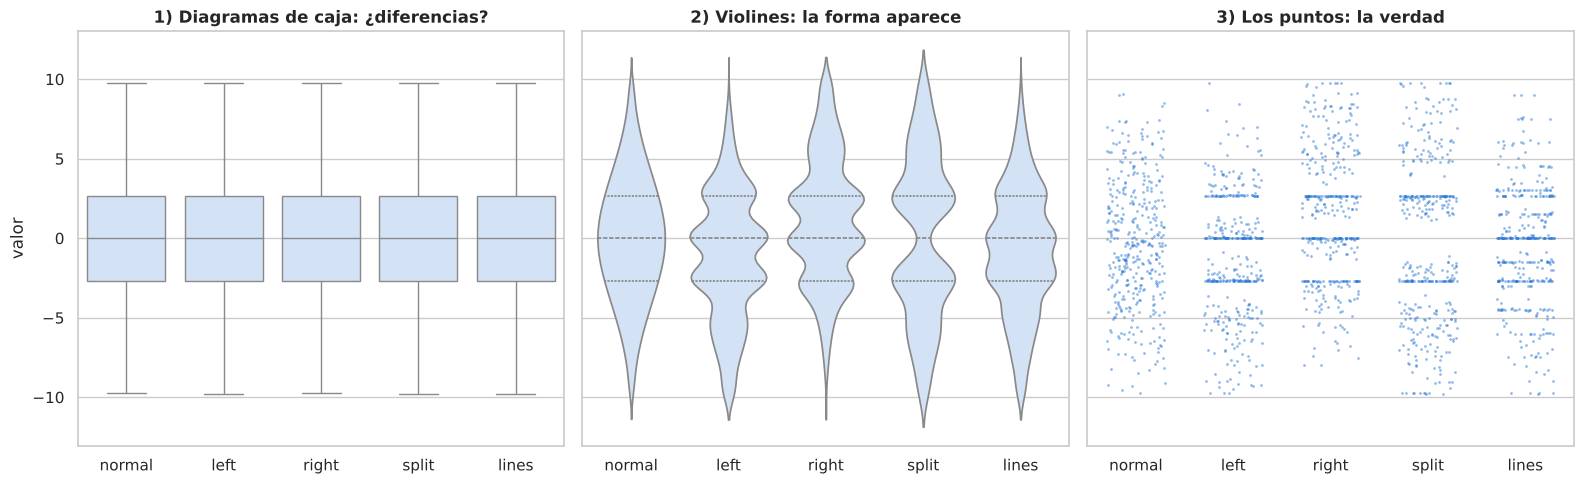

In [9]:
orden_c = ["normal", "left", "right", "split", "lines"]
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
sns.boxplot(data=cajas, x="distribucion", y="valor", order=orden_c, color="#cde2fb", ax=axes[0])
axes[0].set_title("1) Diagramas de caja: ¿diferencias?")
sns.violinplot(data=cajas, x="distribucion", y="valor", order=orden_c, color="#cde2fb", inner="quart", ax=axes[1])
axes[1].set_title("2) Violines: la forma aparece")
sns.stripplot(data=cajas.groupby("distribucion").sample(400, random_state=1), x="distribucion", y="valor",
              order=orden_c, size=2, alpha=0.5, color=AZUL, jitter=0.3, ax=axes[2])
axes[2].set_title("3) Los puntos: la verdad")
for a_ in axes: a_.set_xlabel("")
plt.tight_layout(); plt.show()

Las cinco tienen los mismos cinco números, pero solo `normal` es una distribución "suave"; `left` y `right` acumulan
los datos a un lado y a otro, `split` es **bimodal** (tiene un hueco en el centro) y `lines` concentra los datos en unos pocos valores.
¿Las distinguen las **medidas de forma**?

In [10]:
cajas.groupby("distribucion")["valor"].agg(asimetria="skew", curtosis="kurt", moda=moda).loc[orden_c].round(2)

,asimetria,curtosis,moda
distribucion,,,
normal,0.000,-0.350,0.000
left,-0.110,-0.480,-0.110
right,0.120,-0.470,0.080
split,0.000,-0.980,-3.010
lines,-0.040,-0.390,-0.260


🤔 Solo **a medias**: la curtosis delata a `split` (muy negativa: poca masa en el centro) y la asimetría apunta a `left`/`right`,
pero con valores tan pequeños que no nos alarmarían. `lines` no la delata ningún número. **Ningún resumen sustituye al gráfico.**

## 5. La paradoja de Simpson: Berkeley, 1973
En otoño de 1973, la Universidad de California en Berkeley admitió en sus estudios de posgrado al **44 %** de los hombres que lo
solicitaron y solo al **35 %** de las mujeres. ¿Discriminación? Los datos de los seis departamentos más grandes
(Bickel, Hammel y O'Connell, *Science*, 1975):

In [11]:
berkeley = pd.DataFrame({
    "departamento": list("AABBCCDDEEFF"),
    "sexo": ["Hombre", "Mujer"] * 6,
    "solicitudes": [825, 108, 560, 25, 325, 593, 417, 375, 191, 393, 373, 341],
    "admitidos":   [512,  89, 353, 17, 120, 202, 138, 131,  53,  94,  22,  24],
})
berkeley["tasa_%"] = 100 * berkeley["admitidos"] / berkeley["solicitudes"]

total = berkeley.groupby("sexo")[["solicitudes", "admitidos"]].sum()
total["tasa_%"] = 100 * total["admitidos"] / total["solicitudes"]
total.round(1)

,solicitudes,admitidos,tasa_%
sexo,,,
Hombre,2691,1198,44.500
Mujer,1835,557,30.400


En el total de estos seis departamentos, las mujeres son admitidas en un porcentaje **mucho menor**. Ahora, **departamento a departamento**:

In [12]:
por_dep = berkeley.pivot(index="departamento", columns="sexo", values="tasa_%").round(1)
por_dep["¿quién gana?"] = np.where(por_dep["Mujer"] > por_dep["Hombre"], "Mujeres", "Hombres")
por_dep

sexo,Hombre,Mujer,¿quién gana?
departamento,,,
A,62.100,82.400,Mujeres
B,63.000,68.000,Mujeres
C,36.900,34.100,Hombres
D,33.100,34.900,Mujeres
E,27.700,23.900,Hombres
F,5.900,7.000,Mujeres


😮 **En 4 de los 6 departamentos las mujeres tienen una tasa de admisión MAYOR.** ¿Cómo puede ser que en total salga al revés?

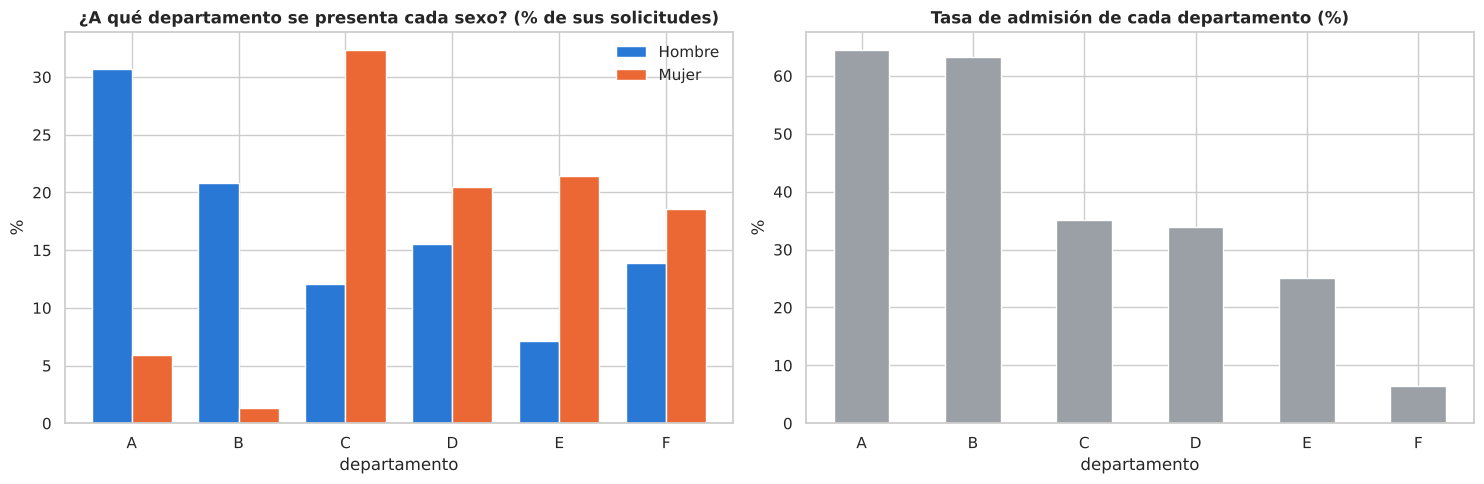

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sol = berkeley.pivot(index="departamento", columns="sexo", values="solicitudes")
(100 * sol / sol.sum()).plot.bar(ax=axes[0], color=[AZUL, NARANJA], width=0.75, rot=0)
axes[0].set_title("¿A qué departamento se presenta cada sexo? (% de sus solicitudes)")
axes[0].set_ylabel("%"); axes[0].legend(frameon=False)
tasa_dep = berkeley.groupby("departamento").apply(lambda g: 100 * g["admitidos"].sum() / g["solicitudes"].sum(), include_groups=False)
tasa_dep.plot.bar(ax=axes[1], color="#9aa0a6", rot=0)
axes[1].set_title("Tasa de admisión de cada departamento (%)"); axes[1].set_ylabel("%")
plt.tight_layout(); plt.show()

🎯 **La explicación:** los hombres se presentaron sobre todo a los departamentos **fáciles** (A y B, que admiten a más del 60 %);
las mujeres, a los **difíciles** (C a F, que admiten a menos del 35 %). La tasa total es una **media ponderada** de las tasas
de cada departamento, y los pesos (dónde se presenta cada grupo) son muy distintos.

Comprobémoslo: la tasa global de cada sexo es la media de sus tasas por departamento **ponderada por sus solicitudes**.

In [14]:
for s, g in berkeley.groupby("sexo"):
    ponderada = np.average(g["tasa_%"], weights=g["solicitudes"])
    simple = g["tasa_%"].mean()
    print(f"{s:6s}: media ponderada por solicitudes = {ponderada:.1f} %  |  media simple de los 6 departamentos = {simple:.1f} %")

Hombre: media ponderada por solicitudes = 44.5 %  |  media simple de los 6 departamentos = 38.1 %
Mujer : media ponderada por solicitudes = 30.4 %  |  media simple de los 6 departamentos = 41.7 %


🤔 Con la **media simple** (cada departamento pesa lo mismo), las mujeres salen por **encima**. Con la ponderada, por debajo.
Agrupar o no agrupar puede **invertir** una conclusión. Esto es la **paradoja de Simpson**, y es la misma idea que ya visteis
con la felicidad (media de países ≠ media de personas) y con los futbolistas (el exponente peso–altura con hombres y mujeres juntos).

### 🚀 Retos de la sesión 1
1. En el bar, ¿cuántos Bill Gates hacen falta para que la **mediana** cambie de forma apreciable? ¿Y el IQR?
2. Ajusta los modelos lineal, potencial y exponencial (`regresiones(x, y)`) al conjunto II de Anscombe. ¿Alguno sirve? Prueba a ajustar una parábola con `np.polyfit(x, y, 2)`.
3. En el conjunto III, quita el atípico y recalcula la recta. ¿Cuánto cambian la pendiente y el $R^2$?
4. Calcula la asimetría y la curtosis de los 13 conjuntos del Datasaurus (para `x` y para `y`). ¿Se distinguen ahora?
5. Inventa tu propio "bar": una muestra de 20 números donde la media sea 50, pero ningún dato esté entre 40 y 60.

---
🏁 **Fin del notebook.**